# Radiator capture · from video to 3D

**What sizeless does.** [sizeless](https://sizeless.co/en) (founded by engineers from ETH Zurich and UC Berkeley, [YC S23](https://www.ycombinator.com/companies/sizeless)) documents underground infrastructure from a phone video. A crew films an open trench with an iPhone Pro for about ten minutes. sizeless turns the video into a centimetre-accurate 3D point cloud, recognises the components (pipe types, diameters, fittings, couplings) and produces the as-built documentation utilities must file: 2D CAD plans (DWG/DXF) and a 3D model for GIS.

<table>
<tr>
<td><img src="https://sizeless.co/assets/scanning2.png" height="190" alt="sizeless 3D point cloud of an open trench"></td>
<td><img src="https://sizeless.co/assets/2d_model.png" height="190" alt="2D CAD as-built plan"></td>
<td><img src="https://sizeless.co/assets/3d_model.png" height="190" alt="3D model and GIS output"></td>
</tr>
<tr><td>3D point cloud of an open trench</td><td>2D CAD as-built plan (DWG/DXF)</td><td>3D model for GIS</td></tr>
</table>

<sub>Images from sizeless.co, linked rather than copied.</sub>

**What this notebook does.** A Sunday prototype of the same pipeline: phone video → 3D reconstruction → recognised components → measurements → documentation, scored against tape-measured ground truth. The stand-in for a trench is a column radiator in my apartment. Its tubes play the pipes, smooth white paint plays wet PVC, furniture limits the stand-off like trench walls do, and bank cards on the floor are there for scale. Filmed on a 720p phone (Oppo A38), no markers. Why these constraints matter: `docs/FINDINGS.md`.

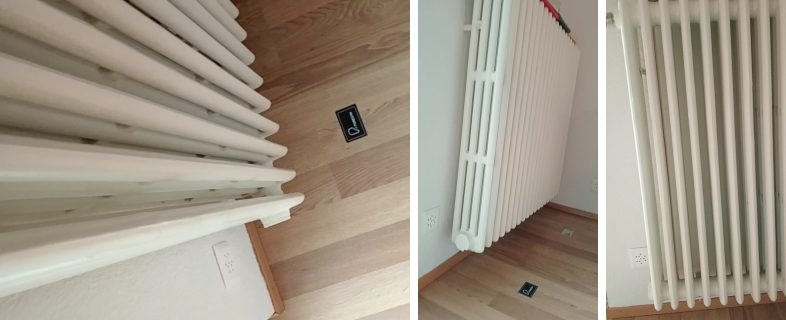

<sub>Clip 1 top-down with the bank card, clip 2 side view, clip 3 front view.</sub>

- **Part 1 · Look at the data**: watch the clips, check what the phone recorded and whether it is good SfM input.
- **Part 2 · Sparse reconstruction**: sharp frames → structure-from-motion (pycolmap, CPU) → interactive 3D view.
- **Part 3 · Lines instead of points**: a quick trial that finds the tubes from line segments and measures their spacing.

In [ ]:
from __future__ import annotations

import base64
import json
import shutil
import subprocess
from dataclasses import dataclass
from pathlib import Path

import cv2
import numpy as np
import yaml
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
import pycolmap
from IPython.display import HTML
from plotly.subplots import make_subplots

pio.renderers.default = "notebook_connected"   # "vscode" if running inside VS Code

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data/raw"
# Clip labels from docs/FINDINGS.md (capture 1), matched by duration.
CLIPS = {
    "clip1": RAW / "VID20261023102101.mp4",   # 47 s, top-down, card visible
    "clip2": RAW / "VID20261023102223.mp4",   # 46 s, arc, then close-up
    "clip3": RAW / "VID20261023102419.mp4",   # 36 s, arc
}
COLORS = {"clip1": "#378ADD", "clip2": "#E8A33D", "clip3": "#1D9E75"}
missing = [p.name for p in CLIPS.values() if not p.exists()]
assert not missing, f"missing in data/raw/: {missing}"

GT = yaml.safe_load(open(ROOT / "data/ground_truth/radiator_2026-10-23.yaml"))
print(GT["measured"])

# --- definitions: watch ---
def make_preview(video: Path, out_dir: Path, long_side: int = 640) -> Path:
    """Small H.264 copy for viewing: displayed orientation, no audio, a few MB. Cached in out_dir."""
    out = Path(out_dir) / f"{video.stem}_{long_side}.mp4"
    if not out.exists():
        out.parent.mkdir(parents=True, exist_ok=True)
        scale = f"scale='if(gt(iw,ih),{long_side},-2)':'if(gt(iw,ih),-2,{long_side})'"
        subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(video), "-an", "-vf", scale,
                        "-c:v", "libx264", "-preset", "veryfast", "-crf", "30", "-pix_fmt", "yuv420p",
                        "-movflags", "+faststart", str(out)], check=True)
    return out


def video_grid(previews: dict[str, Path], height: int = 400) -> HTML:
    """Side-by-side players. Videos are embedded (base64), so they play without a file server."""
    figs = []
    for name, path in previews.items():
        b64 = base64.b64encode(path.read_bytes()).decode()
        figs.append(f'<figure style="margin:0"><video controls muted preload="metadata" '
                    f'style="height:{height}px;max-width:100%" src="data:video/mp4;base64,{b64}"></video>'
                    f'<figcaption style="font-size:12px">{name} · {CLIPS[name].name}</figcaption></figure>')
    return HTML('<div style="display:flex;gap:12px;flex-wrap:wrap;align-items:flex-end">' + "".join(figs) + "</div>")


# --- run: watch ---
previews = {name: make_preview(path, ROOT / "outputs/previews") for name, path in CLIPS.items()}
video_grid(previews)

# Part 1 · Look at the data

Source: [COLMAP tutorial](https://colmap.github.io/tutorial.html): good **texture**, similar **illumination**, high **visual overlap**, and **viewpoints from different positions** rather than rotating in place.

| Section | Question |
|---|---|
| 1.1 · Inventory | What exactly did the phone record? |
| 1.2 · Contact sheet | What does each clip cover, and from where? |
| 1.3 · Quality over time | Where is it blurry, too fast, or badly exposed? |
| 1.4 · Texture | Where would SIFT find features? |


## 1.1 · Inventory
The videos above were filmed three ways: clip 1 looks down over the radiator, clips 2 and 3 walk around it upright. First, what did the phone actually store? Container metadata from ffprobe, plus the real timestamp of every frame.

In [ ]:
# --- definitions: inventory ---
def ffprobe_json(video: Path, *args: str) -> dict:
    out = subprocess.run(["ffprobe", "-v", "error", "-of", "json", *args, str(video)],
                         check=True, capture_output=True, text=True).stdout
    return json.loads(out)


def frame_times(video: Path) -> np.ndarray:
    """Presentation timestamps (s) of every video frame, sorted."""
    d = ffprobe_json(video, "-select_streams", "v:0", "-show_entries", "packet=pts_time")
    return np.sort([float(p["pts_time"]) for p in d["packets"] if p.get("pts_time", "N/A") != "N/A"])


def probe(video: Path) -> dict:
    d = ffprobe_json(video, "-select_streams", "v:0", "-show_entries",
                     "stream=codec_name,width,height,bit_rate:stream_side_data=rotation:format=duration")
    s = d["streams"][0]
    rotation = next((int(sd["rotation"]) for sd in s.get("side_data_list", []) if "rotation" in sd), 0)
    w, h = s["width"], s["height"]
    t = frame_times(video)
    dt = np.diff(t) * 1000
    return {
        "codec": s["codec_name"],
        "stored": f"{w}x{h}",
        "rotation": rotation,
        "displayed": f"{h}x{w}" if rotation % 180 else f"{w}x{h}",
        "duration_s": round(float(d["format"]["duration"]), 1),
        "frames": len(t),
        "mean_fps": round((len(t) - 1) / (t[-1] - t[0]), 2),
        "frame_dt_ms min/med/max": f"{dt.min():.0f}/{np.median(dt):.0f}/{dt.max():.0f}",
        "gaps > 1.5x median": int((dt > 1.5 * np.median(dt)).sum()),
        "bitrate_mbps": round(int(s.get("bit_rate", 0)) / 1e6, 1),
    }


def print_table(rows: dict[str, dict]) -> None:
    keys, names = list(next(iter(rows.values()))), list(rows)
    w = max(len(k) for k in keys)
    print(" " * w + "".join(f"{n:>14}" for n in names))
    for k in keys:
        print(f"{k:<{w}}" + "".join(f"{str(rows[n][k]):>14}" for n in names))


In [ ]:
# --- run: inventory ---
info = {name: probe(path) for name, path in CLIPS.items()}
print_table(info)

**What we see**
- **Same camera, same settings.** All three clips are H.264 at 1280×720 and 8.4 Mbit/s, the phone's maximum. Any difference between them comes from how they were filmed, not from the recording.
- **Clip 1 is landscape, clips 2 and 3 are portrait.** Clip 1 was filmed pointing at the floor, where the phone most likely could not tell which way is up, so it stored no rotation. For reconstruction that means two image shapes: combining clip 1 with clip 3 needs clip 1's frames rotated, or a second camera model.
- **The frame rate is variable.** Nominally 30 fps, actually 27.7–29.1 fps on average. Most frames are 34 ms apart, but gaps reach 135 ms, so up to three frames are dropped at a time. Clip 2 drops the most: 71 gaps, against 18 and 21 in the others. Time therefore has to come from timestamps, not frame numbers.

## 1.2 · Contact sheet
The metadata says *how* each clip was recorded; the frames say *what* was filmed. Twelve evenly spaced frames per clip, in displayed orientation.

In [ ]:
# --- definitions: contact sheet ---
def read_at(video: Path, times_s) -> list[np.ndarray]:
    """RGB frames at the given times. OpenCV applies the rotation metadata, so frames come out as displayed."""
    cap = cv2.VideoCapture(str(video))
    frames = []
    for t in times_s:
        cap.set(cv2.CAP_PROP_POS_MSEC, 1000 * t)
        ok, bgr = cap.read()
        if ok:
            frames.append(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    cap.release()
    return frames


def contact_sheet(video: Path, duration_s: float, n: int = 12, cols: int = 6, title: str = "") -> plt.Figure:
    times = (np.arange(n) + 0.5) * duration_s / n
    frames = read_at(video, times)
    rows = int(np.ceil(n / cols))
    h, w = frames[0].shape[:2]
    fig, ax = plt.subplots(rows, cols, figsize=(2.6 * cols, rows * 2.6 * h / w + 0.6), squeeze=False)
    for a in ax.flat:
        a.axis("off")
    for a, t, f in zip(ax.flat, times, frames):
        a.imshow(f)
        a.set_title(f"{t:.1f} s", fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


In [ ]:
# --- run: contact sheet ---
for name, path in CLIPS.items():
    contact_sheet(path, info[name]["duration_s"], title=f"{name} · {info[name]['duration_s']} s")
    plt.show()

**What we see**
- **Clip 1, top-down.** The camera moves along above the radiator, looking down at the tube tops and the floor. Two bank cards lie on the floor, one dark and one light, small but in view for most of the clip. My feet are in almost every frame. They move between frames, so features on them do not belong to the static scene.
- **Clip 2, side view, then close-up.** The first ~15 s show the radiator's left end with the dark card on the floor. From ~20 s the phone is so close that the tubes fill the frame, and the last few seconds are mostly bare wall.
- **Clip 3, arc.** Starts at the left end, swings round to the front (~19–28 s) and ends close to the tubes. No card is visible in these frames.
- **Coverage is one-sided.** The left side and the front are covered well. The right end sits in a corner against the wall, so there was no room to film it. Any 3D model built from these clips can only be complete on the left and front.
- **The camera moves, it does not just turn.** Clips 2 and 3 travel along the radiator, which gives the parallax structure-from-motion needs.

## 1.3 · Quality over time
The contact sheet shows clip 2 switching from wide views to close-ups, and the inventory found most dropped frames in clip 2. Plotting quality against time shows when things go wrong, and whether moving too fast is the cause. Every 3rd frame: sharpness, image speed, brightness and clipped pixels. Takes about a minute for all three clips.

In [ ]:
# --- definitions: quality over time ---
def frame_stats(video: Path, step: int = 3, flow_width: int = 320) -> dict[str, np.ndarray]:
    """Per sampled frame (every `step`-th): time and four quality measures.

    sharpness   variance of the Laplacian, full-res grey
    brightness  mean grey level, 0-255
    clipped     fraction of pixels <= 5 or >= 250 (crushed shadows / blown highlights)
    motion      median optical-flow speed since the previous sample, full-res px per second
    """
    cap = cv2.VideoCapture(str(video))
    rows, prev, prev_t, i = [], None, None, 0
    while True:
        if i % step:
            if not cap.grab():
                break
            i += 1
            continue
        ok, bgr = cap.read()
        if not ok:
            break
        t = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000
        grey = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        scale = flow_width / grey.shape[1]
        small = cv2.resize(grey, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        motion = np.nan
        if prev is not None and t > prev_t:
            flow = cv2.calcOpticalFlowFarneback(prev, small, None, 0.5, 3, 15, 3, 5, 1.2, 0)
            motion = np.median(np.linalg.norm(flow, axis=2)) / scale / (t - prev_t)
        rows.append((t, cv2.Laplacian(grey, cv2.CV_64F).var(), grey.mean(),
                     np.mean((grey <= 5) | (grey >= 250)), motion))
        prev, prev_t = small, t
        i += 1
    cap.release()
    return dict(zip(["t", "sharpness", "brightness", "clipped", "motion"], np.array(rows).T))


In [ ]:
# --- run: quality over time ---
stats = {name: frame_stats(path) for name, path in CLIPS.items()}

panels = [("sharpness", 1, "sharpness (Laplacian var, log)"), ("motion", 1, "image speed (px/s)"),
          ("brightness", 1, "brightness (0-255)"), ("clipped", 100, "clipped pixels (%)")]
fig = make_subplots(rows=len(panels), cols=1, shared_xaxes=True, vertical_spacing=0.04,
                    subplot_titles=[p[2] for p in panels])
for name, s in stats.items():
    for r, (key, k, _) in enumerate(panels, start=1):
        fig.add_trace(go.Scatter(x=s["t"], y=s[key] * k, mode="lines", name=name, legendgroup=name,
                                 showlegend=r == 1, line=dict(color=COLORS[name], width=1.5)), row=r, col=1)
fig.update_yaxes(type="log", row=1, col=1)
fig.update_xaxes(title_text="time in clip (s)", row=len(panels), col=1)
fig.update_layout(height=800, margin=dict(t=40))
fig.show()

In [ ]:
# Is the blur motion blur? Sharpness against image speed, every sample of every clip.
fig = go.Figure()
for name, s in stats.items():
    fig.add_trace(go.Scatter(x=s["motion"], y=s["sharpness"], mode="markers", name=name,
                             marker=dict(size=4, color=COLORS[name], opacity=0.6)))
fig.update_layout(height=380, xaxis_title="image speed (px/s)", yaxis_title="sharpness",
                  yaxis_type="log", margin=dict(t=20))
fig.show()

**What we see**
- **Clip 2 degrades steadily.** Median sharpness falls from about 30 in its first 5 s to about 5 in its last 5 s.
- **Its close-up is where the camera moves fastest and frames drop.** Image speed peaks at about 130 px/s between 25 and 30 s, and 38 of clip 2's 71 dropped frames fall between 25 and 35 s.
- **Speed alone does not explain sharpness.** In every clip the rank correlation between speed and sharpness is weak (−0.21, 0.26, −0.05). Clip 2's softest stretch, after 40 s, is almost still: the phone is close to bare wall, and there is simply nothing sharp to measure. Laplacian sharpness mixes up *blurry* with *featureless*: ranking frames by it would also discard sharp frames of bare surfaces.
- **Exposure follows the scene.** Clip 2's brightness swings between 111 and 189 as the view moves from bright wall to shaded tubes. Around 25 s in clip 3, the bright balcony door comes into view and up to 22 % of pixels clip.

## 1.4 · Texture
Quality over time suggests that a low score often means little to see. SIFT keypoints show where there *is* something to see, on the sharpest sampled frame of each clip, so blur is not the reason for any gaps. At most 4000 keypoints per frame. OpenCV's SIFT is close to, but not identical to, COLMAP's, so treat counts as indicative.

In [ ]:
# --- definitions: texture ---
def sift_keypoints(rgb: np.ndarray, max_features: int = 4000) -> np.ndarray:
    """(N, 2) SIFT keypoint positions in pixels."""
    grey = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    kps = cv2.SIFT_create(nfeatures=max_features).detect(grey, None)
    return np.array([k.pt for k in kps]).reshape(-1, 2)


In [ ]:
# --- run: texture ---
fig, ax = plt.subplots(1, len(CLIPS), figsize=(5 * len(CLIPS), 6))
for a, (name, path) in zip(ax, CLIPS.items()):
    t = stats[name]["t"][np.nanargmax(stats[name]["sharpness"])]
    img = read_at(path, [t])[0]
    kp = sift_keypoints(img)
    a.imshow(img)
    a.scatter(kp[:, 0], kp[:, 1], s=2, c="#E24B4A")
    a.set_title(f"{name} @ {t:.1f} s · {len(kp)} keypoints")
    a.axis("off")
plt.tight_layout()

**What we see**
- **Even the sharpest frames have few features:** 1298 keypoints in clip 1, 482 in clip 3, 235 in clip 2.
- **They sit around the tubes, not on them.** Keypoints land on tube edges, the dark gaps between tubes, floor grain, the cards, the wall socket and my feet. The white tube faces are almost empty.
- **Clip 1 scores highest because of the floor.** The wood grain fills half its frame; on the radiator itself it does no better than the others.

## Part 1 in short
1. One camera, one setting, three ways of filming: clip 1 top-down in landscape, clips 2 and 3 upright in portrait, all at a variable frame rate.
2. The left side and front are covered, the right end is not; the cards appear in clip 1 and at the start of clip 2.
3. Clip 2's second half is close, fast and drops frames, but much of its low sharpness is bare surface rather than blur.
4. Features live on edges and surroundings, not on the tube faces. That is the core problem for trenches too: smooth pipes give classical features almost nothing.

Of the three clips, **clip 3** is the best start for a reconstruction: it travels along the radiator instead of turning, stays upright, and keeps the most radiator in view without getting as close as clip 2.

# Part 2 · Sparse reconstruction (clip 3)
Clip 3, chosen at the end of Part 1, goes through structure-from-motion. 

## 2.1 · Frames and blur filter
Extract at 4 fps, then keep the sharpest 75 % by the Laplacian score from 1.3. As 1.3 showed, that score also drops on featureless views, so some of what this filter removes is bare surface rather than blur.

In [ ]:
# --- definitions: frames ---
def extract_frames(video: Path, out_dir: Path, fps: float = 4.0) -> list[Path]:
    """Extract frames with ffmpeg (respects the phone's rotation metadata)."""
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    subprocess.run(
        ["ffmpeg", "-v", "error", "-y", "-i", str(video),
         "-vf", f"fps={fps}", "-q:v", "2", str(out_dir / "%04d.jpg")],
        check=True,
    )
    return sorted(out_dir.glob("*.jpg"))


def sharpness(path: Path) -> float:
    """Variance of the Laplacian: low = blurry."""
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return float(cv2.Laplacian(img, cv2.CV_64F).var())


def filter_sharp(frames: list[Path], out_dir: Path, keep_fraction: float = 0.75) -> tuple[list[Path], np.ndarray]:
    """Copy the sharpest `keep_fraction` of frames to out_dir. Returns kept paths and all scores."""
    out_dir = Path(out_dir)
    if out_dir.exists():
        shutil.rmtree(out_dir)
    out_dir.mkdir(parents=True)
    scores = np.array([sharpness(f) for f in frames])
    threshold = np.percentile(scores, 100 * (1 - keep_fraction))
    kept = []
    for f, s in zip(frames, scores):
        if s >= threshold:
            kept.append(Path(shutil.copy(f, out_dir)))
    return kept, scores


In [ ]:
# --- run: frames ---
VIDEO = CLIPS["clip3"]
WORK = ROOT / "outputs/clip3"
all_frames = extract_frames(VIDEO, WORK / "raw", fps=4)
kept, scores = filter_sharp(all_frames, WORK / "frames", keep_fraction=0.75)
thr = np.percentile(scores, 25)

fig = go.Figure(go.Scatter(y=scores, mode="lines+markers", marker=dict(size=4,
        color=np.where(scores >= thr, "#1D9E75", "#E24B4A")), name="sharpness"))
fig.add_hline(y=thr, line_dash="dash", annotation_text="keep above")
fig.update_layout(height=280, xaxis_title="frame", yaxis_title="Laplacian variance", margin=dict(t=20))
fig.show()
print(f"{len(all_frames)} extracted, {len(kept)} kept")

In [ ]:
# Sharpest vs blurriest frames
order = np.argsort(scores)
fig, ax = plt.subplots(2, 4, figsize=(12, 7))
for a, i in zip(ax[0], order[-4:][::-1]): a.imshow(plt.imread(all_frames[i])); a.set_title(f"sharp {scores[i]:.0f}")
for a, i in zip(ax[1], order[:4]):        a.imshow(plt.imread(all_frames[i])); a.set_title(f"blurry {scores[i]:.0f}")
for a in ax.flat: a.axis("off")
plt.tight_layout()

**What we see**
- The filter keeps 107 of 143 frames.
- 10 of the 36 dropped frames come from the first 5 s, where the camera moves at only about 8 px/s (1.3) and much of the view is plain wall. They are dropped for what they show, not for blur.
- Another 11 are from the fast, close end of the clip, after 30 s.

## 2.2 · Structure-from-motion
SIFT (the same 4000-feature budget as the texture check in 1.4) → sequential matching → incremental mapping. About 1 min on a laptop CPU; cached in `outputs/` afterwards (`overwrite=True` to rerun).

In [ ]:
# --- definitions: SfM ---
pycolmap.logging.minloglevel = 1   # hide COLMAP's INFO log lines; warnings and errors still show

def run_sfm(image_dir: Path, out_dir: Path, max_features: int = 4000, overlap: int = 12,
            overwrite: bool = False) -> pycolmap.Reconstruction:
    """SIFT features -> sequential matching -> incremental mapping. Returns the largest model.

    Results are cached in out_dir; pass overwrite=True to recompute.
    """
    image_dir, out_dir = Path(image_dir), Path(out_dir)
    model_dir = out_dir / "0"
    if model_dir.exists() and not overwrite:
        return pycolmap.Reconstruction(model_dir)
    if out_dir.exists():
        shutil.rmtree(out_dir)
    out_dir.mkdir(parents=True)
    db = out_dir / "database.db"

    extraction = pycolmap.FeatureExtractionOptions()
    extraction.sift.max_num_features = max_features
    pycolmap.extract_features(db, image_dir, camera_mode=pycolmap.CameraMode.SINGLE,
                              extraction_options=extraction, device=pycolmap.Device.cpu)

    pairing = pycolmap.SequentialPairingOptions()
    pairing.overlap = overlap
    pairing.loop_detection = False
    pycolmap.match_sequential(db, pairing_options=pairing, device=pycolmap.Device.cpu)

    models = pycolmap.incremental_mapping(db, image_dir, out_dir)
    if not models:
        raise RuntimeError("No model could be reconstructed")
    best = max(models, key=lambda k: models[k].num_reg_images())
    if best != 0:  # keep the largest model at out_dir/0 for caching
        shutil.rmtree(model_dir, ignore_errors=True)
        (out_dir / str(best)).rename(model_dir)
    return pycolmap.Reconstruction(model_dir)


@dataclass
class Cloud:
    xyz: np.ndarray        # (N, 3) points
    rgb: np.ndarray        # (N, 3) uint8 colours
    error: np.ndarray      # (N,) reprojection error, px
    track: np.ndarray      # (N,) number of images observing each point
    cam_centers: np.ndarray  # (M, 3) camera centres, in frame order
    cam_rotations: np.ndarray  # (M, 3, 3) world-to-camera rotations
    names: list[str]


def to_cloud(rec: pycolmap.Reconstruction) -> Cloud:
    pts = list(rec.points3D.values())
    ims = sorted(rec.images.values(), key=lambda im: im.name)
    return Cloud(
        xyz=np.array([p.xyz for p in pts]),
        rgb=np.array([p.color for p in pts], dtype=np.uint8),
        error=np.array([p.error for p in pts]),
        track=np.array([p.track.length() for p in pts]),
        cam_centers=np.array([im.projection_center() for im in ims]),
        cam_rotations=np.array([im.cam_from_world().rotation.matrix() for im in ims]),
        names=[im.name for im in ims],
    )


def clean(cloud: Cloud, max_error: float = 1.5, min_track: int = 3, keep_percentile: float = 97) -> Cloud:
    """Drop high-error / short-track points and far outliers."""
    m = (cloud.error < max_error) & (cloud.track >= min_track)
    xyz = cloud.xyz[m]
    d = np.linalg.norm(xyz - np.median(xyz, axis=0), axis=1)
    m2 = d < np.percentile(d, keep_percentile)
    idx = np.flatnonzero(m)[m2]
    return Cloud(cloud.xyz[idx], cloud.rgb[idx], cloud.error[idx], cloud.track[idx],
                 cloud.cam_centers, cloud.cam_rotations, cloud.names)


def summary(rec: pycolmap.Reconstruction, n_input: int) -> dict:
    return {
        "input_frames": n_input,
        "registered": rec.num_reg_images(),
        "registered_pct": round(100 * rec.num_reg_images() / n_input, 1),
        "points": rec.num_points3D(),
        "mean_reproj_error_px": round(rec.compute_mean_reprojection_error(), 3),
        "mean_track_length": round(rec.compute_mean_track_length(), 2),
    }


In [ ]:
# --- run: SfM ---
rec = run_sfm(WORK / "frames", WORK / "sparse")
summary(rec, n_input=len(kept))

**What we see**
- 87 of the 107 frames register into one model, with a mean reprojection error of 0.66 px. Where frames register, the camera geometry agrees to well under a pixel.
- COLMAP estimated the focal length itself: about 1093 px, a 36° × 61° field of view for the 720 × 1280 frames.
- About 3,600 points, each seen in 6.5 frames on average.
- **The model has no units.** Structure-from-motion from one moving camera recovers shape only up to scale. The camera path is 15.5 model units long, and nothing in the model says how long a unit is.

## 2.3 · Look at it
Red pyramids = where the phone was for each registered frame. Drag to rotate.

In [ ]:
# --- definitions: visualisation ---
def gravity_frame(cloud: Cloud) -> np.ndarray:
    """Rotation that makes 'up' = average image-up direction of the cameras.

    Assumes the phone was held roughly upright. Returns R so that R @ x maps world -> (right, up, back).
    """
    R = cloud.cam_rotations
    up = -np.mean([r.T @ np.array([0, 1, 0]) for r in R], axis=0)
    up /= np.linalg.norm(up)
    fwd = np.mean([r.T @ np.array([0, 0, 1]) for r in R], axis=0)
    fwd -= up * (fwd @ up)
    fwd /= np.linalg.norm(fwd)
    return np.stack([np.cross(fwd, up), up, -fwd])


def frustum_lines(cloud: Cloud, size: float) -> np.ndarray:
    """Line segments (NaN-separated) drawing a small pyramid per camera."""
    segs = []
    corners = np.array([(-.56, -1, 1.2), (.56, -1, 1.2), (.56, 1, 1.2), (-.56, 1, 1.2)]) * size
    for R, c in zip(cloud.cam_rotations, cloud.cam_centers):
        k = c + corners @ R  # camera -> world
        for a, b in [(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (2, 3), (3, 4), (4, 1)]:
            p = np.vstack([c, k])
            segs += [p[a], p[b], [np.nan] * 3]
    return np.array(segs)


def plot_cloud(cloud: Cloud, show_cameras: bool = True, point_size: float = 2.0,
               extra: list[go.BaseTraceType] | None = None, title: str = "") -> go.Figure:
    R = gravity_frame(cloud)
    mu = cloud.xyz.mean(axis=0)
    tf = lambda a: (a - mu) @ R.T  # noqa: E731
    p = tf(cloud.xyz)
    # plotly: x right, y depth, z up
    traces = [go.Scatter3d(x=p[:, 0], y=-p[:, 2], z=p[:, 1], mode="markers", name="points",
                           marker=dict(size=point_size, color=[f"rgb({r},{g},{b})" for r, g, b in cloud.rgb.tolist()]))]
    if show_cameras:
        scale = 0.03 * np.ptp(p, axis=0).max()
        f = frustum_lines(cloud, scale)
        f = np.where(np.isnan(f), np.nan, tf(np.nan_to_num(f)))
        traces.append(go.Scatter3d(x=f[:, 0], y=-f[:, 2], z=f[:, 1], mode="lines", name="cameras",
                                   line=dict(color="#E24B4A", width=2)))
    traces += extra or []
    fig = go.Figure(traces)
    fig.update_layout(title=title, height=650, margin=dict(l=0, r=0, t=40, b=0),
                      scene=dict(aspectmode="data", xaxis_visible=False, yaxis_visible=False, zaxis_visible=False))
    return fig


In [ ]:
# --- run: visualisation ---
cloud = clean(to_cloud(rec))
plot_cloud(cloud, title=f"Clip 3 · {len(cloud.xyz)} points, {len(cloud.cam_centers)} cameras").show()

**What we see**
- The camera path is a smooth arc at a nearly constant distance from the radiator, as the contact sheet in 1.2 suggested.
- The points draw outlines: vertical edges, and horizontal bands along the bottom and top of the radiator. The area between them, where the tube faces are, is almost empty.

## 2.4 · Where are the points, and which frames failed?
1.4 found keypoints on edges, gaps and surroundings, and almost none on flat white surfaces. Two checks on the model itself: where its 3D points land in the images, and which frames failed to register, against the image speed from 1.3.

In [ ]:
# --- definitions: where are the points ---
def frame_time(name: str, fps: float = 4.0) -> float:
    """Time in the clip of an extracted frame; ffmpeg numbers them 0001, 0002, ... at `fps`."""
    return (int(Path(name).stem) - 1) / fps


def smooth_mask(grey: np.ndarray, sigma: float = 2.0, win: int = 15, thr: float = 1.5) -> np.ndarray:
    """True where the image has no fine detail: mean |image - Gaussian blur(sigma)| over win x win pixels below `thr` grey levels.

    Smooth shading counts as smooth (a gradient-based test would miss the shaded tube faces); edges and texture do not.
    SIFT looks for small-scale blobs and corners, so it finds almost nothing in these regions.
    """
    g = grey.astype(np.float32)
    detail = np.abs(g - cv2.GaussianBlur(g, (0, 0), sigma))
    return cv2.blur(detail, (win, win)) < thr


def point_pixels(im: pycolmap.Image) -> np.ndarray:
    """(N, 2) pixel positions of the keypoints in this image that became 3D points."""
    return np.array([p.xy for p in im.points2D if p.has_point3D()]).reshape(-1, 2)


def smooth_share(rec: pycolmap.Reconstruction, image_dir: Path, thr: float = 1.5) -> tuple[float, float]:
    """(% of image area that is smooth, % of 3D-point observations inside it), over all registered frames."""
    area, inside, total = [], 0, 0
    for im in rec.images.values():
        m = smooth_mask(cv2.imread(str(Path(image_dir) / im.name), cv2.IMREAD_GRAYSCALE), thr=thr)
        xy = np.clip(point_pixels(im).astype(int), 0, [m.shape[1] - 1, m.shape[0] - 1])
        area.append(m.mean())
        inside += m[xy[:, 1], xy[:, 0]].sum()
        total += len(xy)
    return 100 * float(np.mean(area)), 100 * inside / total


In [ ]:
# --- run: where are the points ---
for thr in (1.0, 1.5, 2.0):   # does the answer depend on what counts as "smooth"?
    area, pts = smooth_share(rec, WORK / "frames", thr=thr)
    print(f"detail threshold {thr}: smooth area {area:4.1f} % of the frame, {pts:4.1f} % of the 3D points")

by_time = sorted(rec.images.values(), key=lambda im: frame_time(im.name))
fig, ax = plt.subplots(1, 3, figsize=(12, 7))
for a, target in zip(ax, (3, 15, 27)):
    im = min(by_time, key=lambda im: abs(frame_time(im.name) - target))
    grey = cv2.imread(str(WORK / "frames" / im.name), cv2.IMREAD_GRAYSCALE)
    m = smooth_mask(grey)
    xy = point_pixels(im)
    a.imshow(grey, cmap="gray")
    a.imshow(np.ma.masked_where(~m, m), cmap="winter", alpha=0.45)   # blue = smooth
    a.scatter(xy[:, 0], xy[:, 1], s=3, c="#E24B4A")                  # red = 3D points
    a.set_title(f"{frame_time(im.name):.1f} s · {len(xy)} points")
    a.axis("off")
plt.tight_layout()

In [ ]:
# Which frames registered, how many points each saw, and the image speed from 1.3
t_kept = np.array([frame_time(p.name) for p in kept])
seen = {im.name: im.num_points3D for im in rec.images.values()}
ok = np.array([p.name in seen for p in kept])
pts = np.array([seen.get(p.name, 0) for p in kept])
s3 = stats["clip3"]

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=t_kept[ok], y=pts[ok], width=0.2, name="3D points seen", marker_color="#1D9E75"))
fig.add_trace(go.Scatter(x=t_kept[~ok], y=np.zeros((~ok).sum()), mode="markers", name="not registered",
                         marker=dict(color="#E24B4A", symbol="x", size=8)))
fig.add_trace(go.Scatter(x=s3["t"], y=s3["motion"], mode="lines", name="image speed (1.3)",
                         line=dict(color="#888888", width=1)), secondary_y=True)
fig.update_layout(height=320, margin=dict(t=20), xaxis_title="time in clip 3 (s)")
fig.update_yaxes(title_text="3D points seen", secondary_y=False)
fig.update_yaxes(title_text="image speed (px/s)", secondary_y=True)
fig.show()

rank = lambda a: np.argsort(np.argsort(a))  # noqa: E731
valid = ~np.isnan(s3["motion"])
speed = np.interp(t_kept[ok], s3["t"][valid], s3["motion"][valid])
print(f"not registered: {(~ok).sum()} frames, between {t_kept[~ok].min():.1f} and {t_kept[~ok].max():.1f} s")
print(f"rank correlation, 3D points seen vs image speed: {np.corrcoef(rank(pts[ok]), rank(speed))[0, 1]:.2f}")
speed_all = np.interp(t_kept, s3["t"][valid], s3["motion"][valid])
print(f"image speed, registered frames: median {np.median(speed_all[ok]):.0f} px/s, fastest {speed_all[ok].max():.0f}")
print(f"image speed, frames not registered: median {np.median(speed_all[~ok]):.0f} px/s, "
      f"range {speed_all[~ok].min():.0f}–{speed_all[~ok].max():.0f}")

**What we see**
- **Smooth surfaces are invisible to the model.** Regions without fine detail (blue: the shaded tube faces and the wall) cover 57 % of an average frame but hold 4 % of the 3D points. The other 96 % sit on edges and outlines. The threshold changes the numbers, not the picture: 43–67 % of the area holds 2–7 % of the points.
- **Every failed frame is in the last 8 s.** All 20 unregistered frames lie between 28 and 35.5 s, the fast close-up at the end of the clip (1.2, 1.3). The model covers 0–28 s only.
- **3D points seen per frame fall as image speed rises.** From about 390 at 5–10 s to about 90 at 25–30 s, while image speed rises from about 30 to 150 px/s (rank correlation −0.62). Speed barely tracked sharpness (1.3), but it does track registration.
- **Speed alone does not mark the failed frames.** They move at a median of 149 px/s against 46 px/s for registered frames, but the ranges overlap: failed frames run from 8 to 465 px/s, registered ones up to 716 px/s. The failure is one break in the chain of frames at 28 s, after which nothing registers, in a stretch that is both fast and close (1.2). One clip cannot separate speed from closeness.

## What we learned
1. **Camera poses are the easy part.** Where the view has texture, 87 of 107 frames register at 0.66 px error (2.2).
2. **Smooth surfaces are the hard part.** The objects to measure, the white tubes, carry almost no 3D points (1.4, 2.4). Trench pipes are the same case: smooth PVC, painted steel, wet. A diameter cannot be read off surface points; it has to come from edges and silhouettes, or from methods that do not need texture.
3. **Watch image speed, not sharpness.** 3D points per frame fall as the camera moves faster and closer, and the model breaks in the fastest, closest stretch (2.4); the sharpness score mostly tracks content and drops sharp but bare frames (1.3, 2.1). Image speed, which optical flow measures cheaply, is a plausible live warning for a capture app, still to be tested on clips where speed and distance vary separately.
4. **Coverage is fixed at capture time.** The right end in the corner was never filmed (1.2), and no processing recovers it. In a trench, walls and depth limit viewpoints the same way, so the app has to show what is still missing before the trench is backfilled.
5. **Scale needs a reference.** The model has no units (2.2). The bank cards appear in clip 1 and early in clip 2, but not in clip 3.
6. **Moving things are in the shot.** Feet appear in most of clip 1 (1.2). In a trench it is workers and excavators; they need masking before reconstruction.

## Gaps against sizeless
| Step | sizeless | This demo |
|---|---|---|
| Capture | Guided iPhone Pro app, about 10 min per trench, works without GPS | Unguided 36–47 s clips from a 720p phone |
| 3D | Metric 3D model from their SLAM engine, built for wet, muddy trenches with moving excavators | Sparse SfM, about 3,600 points, no scale, static scene |
| Components | Recognises pipe types, diameters, fittings, couplings | None |
| Measurements | Measurements and billable quantities | None yet; tape ground truth recorded |
| Output | CAD (DWG/DXF), BIM/GIS, crew voice notes anchored in 3D | Interactive 3D view |

Sources: [sizeless.co](https://sizeless.co/en), [YC launch post](https://www.ycombinator.com/companies/sizeless). The report discusses each gap.

# Part 3 · A quick trial: lines instead of points
Part 2 left the tubes out of the model. 2.4 showed why: the tube faces are smooth, and the dark gaps between the tubes are long straight edges. A feature has to stand out in every direction, but a spot on a straight edge looks like the next spot along it (the *aperture problem*), so SIFT finds points only where an edge ends or turns. A line as a whole, though, is easy to find and to place.

This part tests whether the tubes are in the frames as lines, reusing what already works:
- **The camera poses from Part 2.** They were the solid part (2.2), so they are reused, not estimated again.
- **[LSD](https://www.ipol.im/pub/art/2012/gjmr-lsd/)**, a line-segment detector that ships with OpenCV, so nothing new to install.
- **One shortcut: the tubes are vertical.** Seen from above, a vertical line is a single point. A segment in one frame and that frame's camera centre span a plane; seen from above, that plane is a ray from the camera through the line. The rays of one tube from many frames cross at one spot, so counting rays per grid cell (a Hough-style vote) finds the tubes without matching lines between frames.

General line-reconstruction tools exist ([Line3D++](https://github.com/manhofer/Line3Dpp), [LIMAP](https://github.com/cvg/limap)). They match and triangulate lines in any direction, but need a C++ build. The vertical shortcut fits in a few cells, which is enough to answer the question.

## 3.1 · Line segments in the frames
LSD on the same three frames as 2.4. Segments shorter than 40 px are dropped: they are mostly noise and texture, not structure.

In [ ]:
# --- definitions: line segments ---
LSD = cv2.createLineSegmentDetector()


def detect_lines(grey: np.ndarray, min_len: float = 40.0) -> np.ndarray:
    """(N, 4) line segments x1, y1, x2, y2 found by LSD, at least min_len pixels long."""
    seg = LSD.detect(grey)[0]
    seg = np.zeros((0, 4)) if seg is None else seg.reshape(-1, 4)
    return seg[np.hypot(seg[:, 2] - seg[:, 0], seg[:, 3] - seg[:, 1]) >= min_len]

In [ ]:
# --- run: line segments ---
fig, ax = plt.subplots(1, 3, figsize=(12, 7))
for a, target in zip(ax, (3, 15, 27)):
    im = min(by_time, key=lambda im: abs(frame_time(im.name) - target))
    grey = cv2.imread(str(WORK / "frames" / im.name), cv2.IMREAD_GRAYSCALE)
    seg = detect_lines(grey)
    a.imshow(grey, cmap="gray")
    for x1, y1, x2, y2 in seg:
        a.plot([x1, x2], [y1, y2], color="#1D9E75", lw=1)
    a.set_title(f"{frame_time(im.name):.1f} s · {len(seg)} segments")
    a.axis("off")
plt.tight_layout()

n_seg = [len(detect_lines(cv2.imread(str(WORK / "frames" / im.name), cv2.IMREAD_GRAYSCALE))) for im in rec.images.values()]
print(f"segments of 40 px or more per registered frame: median {np.median(n_seg):.0f}")
print(f"3D points seen per registered frame (2.4): median {np.median([im.num_points3D for im in rec.images.values()]):.0f}")

**What we see**
- **The segments find what SIFT missed.** They run along the tube edges and the gaps between the tubes in all three frames, including at 27 s, where 2.4 found only 94 3D points.
- A median of 160 segments per frame against 279 3D points, but each segment is at least 40 px of edge, where a point marks one spot.

## 3.2 · Votes from above
Every segment becomes a plane through its frame's camera centre, in the model's coordinates from 2.2. The vertical is the direction most of those planes contain; it is estimated from the lines themselves and compared with the camera-based "up" from 2.3. Then each near-vertical segment casts its ray into a top-view grid. A sharpening step (difference of Gaussians) keeps compact crossings and removes the broad haze where many rays overlap anyway.

In [ ]:
# --- definitions: votes from above ---
@dataclass
class Planes:
    centers: np.ndarray  # (N, 3) camera centre of the frame each segment was seen in
    normals: np.ndarray  # (N, 3) unit normal of the plane through that centre and the segment
    ends: np.ndarray     # (N, 2, 3) viewing directions of the segment's two end points, world frame


def segment_planes(rec: pycolmap.Reconstruction, image_dir: Path, min_len: float = 40.0) -> Planes:
    """Detect segments in every registered frame and turn each into a plane in the model's world frame."""
    C, N, E = [], [], []
    for im in sorted(rec.images.values(), key=lambda im: im.name):
        K_inv = np.linalg.inv(rec.cameras[im.camera_id].calibration_matrix())
        R = im.cam_from_world().rotation.matrix()
        grey = cv2.imread(str(Path(image_dir) / im.name), cv2.IMREAD_GRAYSCALE)
        for x1, y1, x2, y2 in detect_lines(grey, min_len):
            d = (R.T @ K_inv @ np.array([[x1, x2], [y1, y2], [1.0, 1.0]])).T   # viewing directions of both ends
            n = np.cross(d[0], d[1])
            C.append(im.projection_center())
            N.append(n / np.linalg.norm(n))
            E.append(d)
    return Planes(np.array(C), np.array(N), np.array(E))


def vertical_direction(planes: Planes, guess: np.ndarray, max_deg=(10, 5, 5)) -> np.ndarray:
    """The direction most segment planes contain.

    A plane contains direction v when its normal is perpendicular to v, so v is the direction most perpendicular
    to the normals (their smallest singular vector), refit on the planes within max_deg of containing it.
    """
    v = guess / np.linalg.norm(guess)
    for deg in max_deg:
        near = np.abs(planes.normals @ v) < np.sin(np.radians(deg))
        v = np.linalg.svd(planes.normals[near])[2][-1]
        v *= np.sign(v @ guess)
    return v


def top_view(up: np.ndarray) -> np.ndarray:
    """(2, 3) matrix: world point -> 2D coordinates seen from above, i.e. perpendicular to `up`."""
    e1 = np.cross(up, [1.0, 0.0, 0.0])
    e1 /= np.linalg.norm(e1)
    return np.stack([e1, np.cross(up, e1)])


def vertical_rays(planes: Planes, up: np.ndarray, max_deg: float = 3.0):
    """Top-view rays (start c, unit direction u) of the segments whose plane contains the vertical within max_deg,
    and the mask of which segments those are. Seen from above, such a plane is a ray from the camera."""
    keep = np.abs(planes.normals @ up) < np.sin(np.radians(max_deg))
    B = top_view(up)
    c = planes.centers[keep] @ B.T
    n = planes.normals[keep] @ B.T
    u = np.c_[-n[:, 1], n[:, 0]]
    u /= np.linalg.norm(u, axis=1, keepdims=True)
    look = planes.ends[keep].mean(axis=1) @ B.T
    u *= np.sign(np.sum(u * look, axis=1))[:, None]   # point each ray the way its camera looks
    return c, u, keep


def vote(c: np.ndarray, u: np.ndarray, lo: np.ndarray, hi: np.ndarray, cell: float) -> np.ndarray:
    """Hough-style vote: every ray adds 1 to each grid cell it crosses. Rows run along the second top-view axis."""
    nx, ny = np.ceil((hi - lo) / cell).astype(int)
    votes = np.zeros((ny, nx))
    corners = np.array([lo, hi, [lo[0], hi[1]], [hi[0], lo[1]]])
    reach = np.linalg.norm(c[:, None] - corners[None], axis=2).max()
    lam = np.arange(0, reach, cell / 2)
    for ci, ui in zip(c, u):
        ij = np.floor((ci + lam[:, None] * ui - lo) / cell).astype(int)
        ij = np.unique(ij[(ij >= 0).all(axis=1) & (ij[:, 0] < nx) & (ij[:, 1] < ny)], axis=0)
        votes[ij[:, 1], ij[:, 0]] += 1
    return votes


def sharpen(votes: np.ndarray, fine: float = 1.5, coarse: float = 8.0) -> np.ndarray:
    """Difference of Gaussians (sigmas in grid cells): keeps compact crossings, removes the broad haze."""
    return cv2.GaussianBlur(votes, (0, 0), fine) - cv2.GaussianBlur(votes, (0, 0), coarse)

In [ ]:
# --- run: votes from above ---
planes = segment_planes(rec, WORK / "frames")
up_cam = gravity_frame(cloud)[1]
up = vertical_direction(planes, up_cam)
c, u, keep = vertical_rays(planes, up)
B = top_view(up)
pts2d = cloud.xyz @ B.T
CELL = 0.01   # grid cell in model units; the camera path is 15.5 units long (2.2)
lo = np.percentile(pts2d, 2, axis=0) - 0.3
hi = np.percentile(pts2d, 98, axis=0) + 0.3
sharp = sharpen(vote(c, u, lo, hi, CELL))
print(f"{len(planes.normals)} segments, {keep.sum()} on near-vertical planes ({100 * keep.mean():.0f} %)")
print(f"vertical from the lines vs camera 'up' (2.3): {np.degrees(np.arccos(np.clip(up @ up_cam, -1, 1))):.1f}° apart")

ext = [lo[0], hi[0], lo[1], hi[1]]
cams2d = cloud.cam_centers @ B.T
fig, ax = plt.subplots(1, 2, figsize=(12, 7), sharex=True, sharey=True)
ax[0].imshow(sharp, origin="lower", extent=ext, cmap="magma", vmin=0, vmax=np.percentile(sharp, 99.9))
ax[0].set_title("line votes from above")
ax[1].imshow(sharp, origin="lower", extent=ext, cmap="gray_r", vmin=0, vmax=np.percentile(sharp, 99.9))
ax[1].scatter(*pts2d.T, s=2, c="#E24B4A", label="3D points (2.2)")
ax[1].set_title("same, with the 3D points")
ax[1].legend(loc="upper right")
for a in ax:
    a.set_xlim(lo[0], hi[0]); a.set_ylim(lo[1], hi[1]); a.set_aspect("equal")
plt.tight_layout()

**What we see**
- **The scene is vertical lines.** 90 % of the 13,099 segments lie on near-vertical planes, so the vertical can be read off the lines. It is 10.8° away from the camera-based "up" of 2.3, which assumed the phone was held upright; the tilted frame at 27 s in 3.1 shows it was not.
- **The tubes appear as a row of separate spots.** Along the radiator front the votes form compact, evenly spaced spots. The 3D points lie in the same area but scatter over it.
- **Where the 3D points did catch a vertical edge, the votes agree.** The tight cluster of 3D points near (3.9, 4.1) is the full-height vertical edge at the left of the 3 s and 15 s frames in 2.4, and it sits on a sharp vote spot.
- **The spots are stretched along the viewing direction.** The cameras are to the lower left, outside the plot. From their arc, depth is less certain than side-to-side position: parallax only constrains depth through the small baseline between views.

## 3.3 · Tube spacing and height
The strongest crossings are taken as vertical lines, and the straight row through most of them as the radiator front. Along that row, the repeat distance of the votes is the tube spacing; the same is done for the 3D points from 2.2. The height of the tubes comes from where the segments that support the row start and end. Both are in model units, but their ratio is not: tape says 55 mm spacing over 960 mm height. That makes the spacing checkable without any scale, assuming the segments run the full height of the radiator.

In [ ]:
# --- definitions: spacing and height ---
def find_peaks(img: np.ndarray, lo: np.ndarray, cell: float, pct: float = 99.5, win: int = 9):
    """Local maxima above the pct-th percentile: (N, 2) top-view positions and (N,) strengths."""
    ij = np.argwhere((img == cv2.dilate(img, np.ones((win, win)))) & (img > np.percentile(img, pct)))
    return lo + (ij[:, ::-1] + 0.5) * cell, img[ij[:, 0], ij[:, 1]]


def fit_row(xy: np.ndarray, w: np.ndarray, tol: float = 0.1):
    """Straight line through the most peak strength (every pair of peaks tried), refit by weighted PCA of its inliers.

    Returns (origin, unit direction, inlier mask).
    """
    best_score, best = -1.0, None
    for i in range(len(xy)):
        for j in range(i + 1, len(xy)):
            a = (xy[j] - xy[i]) / np.linalg.norm(xy[j] - xy[i])
            inl = np.abs((xy - xy[i]) @ np.array([a[1], -a[0]])) < tol
            if w[inl].sum() > best_score:
                best_score, best = w[inl].sum(), inl
    o = np.average(xy[best], axis=0, weights=w[best])
    a = np.linalg.svd((xy[best] - o) * np.sqrt(w[best])[:, None])[2][0]
    return o, a, best


def profile_along(xy: np.ndarray, w: np.ndarray, origin, axis, half_width: float, step: float, extent: float) -> np.ndarray:
    """Weights w of 2D positions xy within half_width of the row, summed in bins of `step` along it."""
    s = (xy - origin) @ axis
    near = np.abs((xy - origin) @ np.array([axis[1], -axis[0]])) < half_width
    return np.histogram(s[near], np.arange(-extent, extent + step, step), weights=w[near])[0]


def period(profile: np.ndarray, step: float, min_lag: float, max_lag: float) -> tuple[float, float]:
    """Strongest repeat distance of a profile: the lag of highest autocorrelation between min_lag and max_lag.

    Returns (lag, autocorrelation there: 1 = a perfect repeat, 0 = none).
    """
    p = profile - profile.mean()
    ac = np.correlate(p, p, "full")[len(p) - 1:] / (p @ p)
    lag = np.arange(len(ac)) * step
    k = np.argmax(np.where((lag >= min_lag) & (lag <= max_lag), ac, -np.inf))
    return float(lag[k]), float(ac[k])


def end_heights(planes: Planes, keep, c, u, up, x0, tol: float = 0.015) -> np.ndarray:
    """Heights along `up` of the end points of the segments whose top-view ray passes within tol of x0."""
    rel = x0 - c
    hit = (np.sum(rel * u, axis=1) > 0) & (np.abs(rel[:, 0] * u[:, 1] - rel[:, 1] * u[:, 0]) < tol)
    B = top_view(up)
    ends = planes.ends[keep][hit]                     # (M, 2, 3)
    d2 = ends @ B.T                                   # their directions seen from above
    mu = np.einsum("mk,mjk->mj", rel[hit], d2) / np.einsum("mjk,mjk->mj", d2, d2)
    return ((planes.centers[keep][hit][:, None] + mu[..., None] * ends) @ up).ravel()

In [ ]:
# --- run: spacing and height ---
xy, w = find_peaks(sharp, lo, CELL)
origin, axis, on_row = fit_row(xy, w)
extent = np.abs((xy[on_row] - origin) @ axis).max() + 0.2
grid_xy = lo + (np.argwhere(np.ones_like(sharp, bool))[:, ::-1] + 0.5) * CELL
print(f"{on_row.sum()} of {len(xy)} vote peaks lie on one straight row")
for hw in (0.05, 0.1, 0.2):   # does the answer depend on how wide a band around the row is used?
    pl = period(profile_along(grid_xy, np.clip(sharp, 0, None).ravel(), origin, axis, hw, CELL, extent), CELL, 0.06, 0.5)
    pp = period(profile_along(pts2d, np.ones(len(pts2d)), origin, axis, hw, CELL, extent), CELL, 0.06, 0.5)
    print(f"band ±{hw}: repeat distance, lines {pl[0]:.2f} units (autocorrelation {pl[1]:.2f}); "
          f"3D points {pp[0]:.2f} units ({pp[1]:.2f})")
spacing_u = period(profile_along(grid_xy, np.clip(sharp, 0, None).ravel(), origin, axis, 0.1, CELL, extent), CELL, 0.06, 0.5)[0]

h = np.concatenate([end_heights(planes, keep, c, u, up, x0) for x0 in xy[on_row]])
tape = GT["measured"]
for q in (1, 2):
    bottom, top = np.percentile(h, [q, 100 - q])
    print(f"tube height ({q}th–{100 - q}th percentile of segment ends): {top - bottom:.2f} units → "
          f"spacing {tape['radiator_height'] * spacing_u / (top - bottom):.0f} mm if the radiator is "
          f"{tape['radiator_height']} mm tall (tape: {tape['tube_center_spacing']} mm)")

prof_l = profile_along(grid_xy, np.clip(sharp, 0, None).ravel(), origin, axis, 0.1, CELL, extent)
prof_p = profile_along(pts2d, np.ones(len(pts2d)), origin, axis, 0.1, CELL, extent)
s_bins = -extent + (np.arange(len(prof_l)) + 0.5) * CELL
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(s_bins, prof_l / prof_l.max(), color="#1D9E75", label="line votes")
ax[0].plot(s_bins, prof_p / prof_p.max(), color="#E24B4A", label="3D points (2.2)")
ax[0].set_xlabel("position along the radiator front (model units)"); ax[0].legend()
ax[1].hist(h, 150, color="#888888")
for v in np.percentile(h, [2, 98]):
    ax[1].axvline(v, color="k", ls="--", lw=1)
ax[1].set_xlabel("height of segment ends (model units)")
plt.tight_layout()

**What we see**
- 18 of the 27 strongest spots lie on one straight row: the radiator front.
- **The votes repeat every 0.36–0.37 units** along it, with autocorrelation 0.42–0.67 depending on the band width. The 3D points hint at a similar repeat (0.37–0.38) in the narrow bands, but weakly (0.30–0.33), and in the widest band they lock onto half of it (0.19).
- **The segment ends stop sharply at two heights,** the top and bottom of the tubes, 6.0–6.2 units apart.
- **Spacing over height gives 56–58 mm for a 960 mm radiator, against 55 mm on the tape:** 2–5 % off, without any scale reference.

## 3.4 · Points and lines in one model
Each vote spot on the row from 3.3 becomes a vertical line, from where its segments start to where they end. Shown with the 3D points from 2.2, in a frame whose "up" is the vertical from the lines (3.2), so the lines stand upright.

In [ ]:
# --- definitions: points and lines in one model ---
def vertical_segments(planes: Planes, keep, c, u, up, peaks: np.ndarray, q: float = 2.0) -> np.ndarray:
    """(M, 2, 3) world end points of one vertical line per top-view peak, from the q-th to the (100-q)-th
    percentile of the heights where its supporting segments end."""
    B = top_view(up)
    out = []
    for x0 in peaks:
        bottom, top = np.percentile(end_heights(planes, keep, c, u, up, x0), [q, 100 - q])
        base = B.T @ x0                      # the peak's position, at height 0
        out.append([base + bottom * up, base + top * up])
    return np.array(out)


def upright_frame(cloud: Cloud, up: np.ndarray) -> np.ndarray:
    """Like gravity_frame (2.3), but with a given 'up': rows (right, up, back)."""
    back = gravity_frame(cloud)[2]
    back = back - (back @ up) * up
    back /= np.linalg.norm(back)
    return np.stack([np.cross(-back, up), up, back])


def plot_points_and_lines(cloud: Cloud, R: np.ndarray, segments: np.ndarray, title: str = "") -> go.Figure:
    """3D points (grey), camera path (red) and line segments (green) in frame R; plotly z is up."""
    mu = cloud.xyz.mean(axis=0)
    tf = lambda a: (a - mu) @ R.T  # noqa: E731
    p, cam = tf(cloud.xyz), tf(cloud.cam_centers)
    seg = np.concatenate([np.vstack([tf(s), [[np.nan] * 3]]) for s in segments])
    fig = go.Figure([
        go.Scatter3d(x=p[:, 0], y=-p[:, 2], z=p[:, 1], mode="markers", name="3D points (2.2)",
                     marker=dict(size=1.5, color="#AAAAAA")),
        go.Scatter3d(x=cam[:, 0], y=-cam[:, 2], z=cam[:, 1], mode="lines", name="camera path",
                     line=dict(color="#E24B4A", width=3)),
        go.Scatter3d(x=seg[:, 0], y=-seg[:, 2], z=seg[:, 1], mode="lines", name="vertical lines (3.3)",
                     line=dict(color="#1D9E75", width=5)),
    ])
    fig.update_layout(title=title, height=650, margin=dict(l=0, r=0, t=40, b=0),
                      scene=dict(aspectmode="data", xaxis_visible=False, yaxis_visible=False, zaxis_visible=False))
    return fig

In [ ]:
# --- run: points and lines in one model ---
segments = vertical_segments(planes, keep, c, u, up, xy[on_row])
s_row = (xy[on_row] - origin) @ axis
print(f"{len(segments)} vertical lines over {np.ptp(s_row):.2f} units of radiator front = "
      f"{np.ptp(s_row) / spacing_u:.1f} tube spacings of {spacing_u:.2f}")
plot_points_and_lines(cloud, upright_frame(cloud, up), segments,
                      title=f"Clip 3 · {len(cloud.xyz)} points and {len(segments)} vertical lines").show()

**What we see**
- **The lines fill what the points left empty.** From the front, the 3D points outline the radiator: its left edge and bands along the top and bottom (2.3). The 18 vertical lines stand between those bands, across the radiator front.
- **Their ends meet the point bands.** The tops and bottoms of the lines line up with the top and bottom bands of 3D points, so the height used in 3.3 is the radiator's, as assumed there.
- **More lines than tubes.** 18 lines over 7.3 tube spacings: one tube gives more than one line, its edges and the gaps beside it. Grouping lines into tubes, and tubes into cylinders, is the next step.
- **From above, the lines sit on the radiator front,** inside the point cloud, in one straight row.

## Part 3 in short
1. **The tubes are in the frames, as lines.** Where SIFT points failed (2.4), line segments find the tube edges, and voting them from above recovers the tubes as a regular row (3.2). In 3D, the lines fill the radiator front that the points left empty (3.4).
2. **A first measurement, without scale.** Tube spacing relative to height matches the tape to within 2–5 % (3.3). It assumes the segments span the radiator's full height, which the sharp top and bottom of the height histogram support.
3. **Positions, not diameters, yet.** A tube's visible edge is where the line of sight grazes the cylinder, so it shifts as the camera moves; the edges are tangents, not fixed lines. A diameter needs a cylinder fitted to those tangents.
4. **The shortcut is the vertical.** Trench pipes mostly run horizontally along the trench. The same vote works along any dominant direction, which the plane trick of 3.2 could estimate (untested here); for pipes in several directions, a general line mapper such as LIMAP is the next step.